# The dataset

Photographs of *Hippocampus guttulatus* and *Hippocampus hippocampus* taken underwater in the
Thau lagoon between March 2022 and October 2025. An expert observer determined the species, the
sex and the identity of each individual.

This notebook makes **Table 1**, **Table 2** and **Figure 1** of the paper. It needs only the photo
database and the uncropped photographs.

## Settings

Every location comes from `../config.toml`, a copy of `../config.example.toml`.

In [7]:
import tomllib
from pathlib import Path

ROOT = Path.cwd().parent
CONFIG = tomllib.loads((ROOT / "config.toml").read_text())

# Relative paths in config.toml start at the folder that holds it.
DATABASE = ROOT / Path(CONFIG["data_root"]).expanduser() / "seahorse_photo_database.xlsx"
PHOTOGRAPHS = ROOT / Path(CONFIG["photographs"]).expanduser()
FIGURE_DIR = ROOT / Path(CONFIG["output_dir"]).expanduser() / "figures"
for path in (DATABASE, PHOTOGRAPHS):
    assert path.exists(), f"Not found: {path}. Check the paths in {ROOT / 'config.toml'}."
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## Tables and figures

In [8]:
import matplotlib.pyplot as plt

PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#6E6E6E"]
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "CMU Serif", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True, "axes.unicode_minus": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "figure.figsize": (7.0, 4.2), "figure.dpi": 130,
    "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.04,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#D8DEE9", "grid.linewidth": 0.6, "grid.alpha": 0.45,
    "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "legend.frameon": False,
    "lines.linewidth": 2.0, "lines.markersize": 5,
})

## The photo database 

In [ ]:
import pandas as pd
from skrub import TableReport

photos = pd.read_excel(DATABASE, sheet_name="Photos")
individuals = pd.read_excel(DATABASE, sheet_name="Individual_Summary")
for frame in (photos, individuals):  # the database abbreviates the genus; the paper spells it out
    frame["species"] = frame["species"].str.replace("H.", "Hippocampus", regex=False)

photos["observation_date"] = pd.to_datetime(photos["observation_date"], errors="coerce")
individuals["follow_up_days"] = (
    pd.to_datetime(individuals["last_observation"], errors="coerce")
    - pd.to_datetime(individuals["first_observation"], errors="coerce")
).dt.days

observations = photos.drop_duplicates(subset=["unique_id", "observation_date"])
print(f"{len(photos):,} photographs of {individuals['unique_id'].nunique()} individuals "
      f"in {len(observations):,} observations")
print(f"{photos['observation_date'].min():%Y-%m-%d} to {photos['observation_date'].max():%Y-%m-%d}")
print(individuals.groupby("species")["unique_id"].nunique().to_dict())
TableReport(photos, verbose=0)

35,914 photographs of 474 individuals in 2,493 observations
2022-03-25 to 2025-10-28
{'Hippocampus guttulatus': 461, 'Hippocampus hippocampus': 13}


""


### Table 1 — Summary statistics by species and sex

Species and sex belong to the individual, so both come from `Individual_Summary`. The photograph
rows store an unsexed animal as a missing value, not as "Unknown", so they would drop it.

In [ ]:
from IPython.display import Markdown, display
from itables import init_notebook_mode, show

init_notebook_mode(all_interactive=True)  # every DataFrame shown from here on is interactive

GROUP = ["species", "sex"]
SEX = pd.CategoricalDtype(["Male", "Female", "Unknown"], ordered=True)  # the row order of Table 1


def show_table(frame, caption, label, column_format):
    """Display the table, sortable and searchable, then its booktabs LaTeX."""
    latex = (frame.style.hide(axis="index")
             .to_latex(hrules=True, caption=caption, label=label, position="htbp",
                       position_float="centering", column_format=column_format)
             .replace("±", r"$\pm$"))  # the paper sets ± in math mode
    show(frame, showIndex=False, paging=False)
    display(Markdown(f"**`{label}`**\n\n```latex\n{latex}\n```"))


def median_iqr(values):
    """The median and the interquartile range, as 'median (P25--P75)'."""
    return f"{values.median():.0f} ({values.quantile(0.25):.0f}--{values.quantile(0.75):.0f})"


photos_per_observation = (
    photos.groupby(["unique_id", "observation_date"]).size().rename("photos").reset_index()
    .merge(individuals[["unique_id", *GROUP]], on="unique_id")
)
per_individual = individuals.astype({"sex": SEX}).groupby(GROUP, observed=True).agg(**{
    "N": ("unique_id", "size"),
    "FU med/max (d)": ("follow_up_days", lambda days: f"{days.median():.0f}/{days.max():.0f}"),
    "Obs/ind. (IQR)": ("observation_count", median_iqr),
})
per_observation = (photos_per_observation.astype({"sex": SEX}).groupby(GROUP, observed=True)
                   ["photos"].agg(median_iqr).rename("Photos/obs (IQR)"))

summary = (per_individual.join(per_observation).reset_index()
           .rename(columns={"species": "Species", "sex": "Sex"}))
summary["Species"] = summary["Species"].str.replace("Hippocampus", "H.")
show_table(summary, label="tab:summary_statistics_by_species_and_sex", column_format="llrrrr",
           caption="Summary statistics by species and sex. FU: follow-up time in days. Obs/ind.: "
                   "number of observations per individual. Photos/obs: number of photos per "
                   "observation. IQR: interquartile range.")

**`tab:summary_statistics_by_species_and_sex`**

```latex
\begin{table}[htbp]
\centering
\caption{Summary statistics by species and sex. FU: follow-up time in days. Obs/ind.: number of observations per individual. Photos/obs: number of photos per observation. IQR: interquartile range.}
\label{tab:summary_statistics_by_species_and_sex}
\begin{tabular}{llrrrr}
\toprule
Species & Sex & N & FU med/max (d) & Obs/ind. (IQR) & Photos/obs (IQR) \\
\midrule
H. guttulatus & Male & 213 & 40/1015 & 3 (1--7) & 13 (10--17) \\
H. guttulatus & Female & 185 & 40/1094 & 2 (1--8) & 13 (10--16) \\
H. guttulatus & Unknown & 63 & 0/41 & 1 (1--1) & 15 (12--20) \\
H. hippocampus & Male & 8 & 2/87 & 2 (1--2) & 16 (13--41) \\
H. hippocampus & Female & 5 & 39/108 & 5 (5--7) & 13 (10--32) \\
\bottomrule
\end{tabular}
\end{table}

```

### Table 2 — Inter-observation gap statistics by species

How long an individual goes unseen between two sightings. This sets how much the appearance can
change between two observations of the same animal.

In [ ]:
dates = (photos[["unique_id", "observation_date", "species"]]
         .drop_duplicates(subset=["unique_id", "observation_date"])
         .sort_values(["unique_id", "observation_date"]))
dates["gap_days"] = dates.groupby("unique_id")["observation_date"].diff().dt.days
# The first sighting has no gap (NaN), and same-day rows are not gaps.
gaps = dates.query("gap_days > 0").astype({"gap_days": int})

gap_table = gaps.groupby("species")["gap_days"].agg(**{
    "n gaps": "size",
    "Min (d)": "min",
    "P25 (d)": lambda days: int(days.quantile(0.25)),
    "Median (d)": lambda days: int(days.median()),
    "P75 (d)": lambda days: int(days.quantile(0.75)),
    "Max (d)": "max",
    "Mean ± SD": lambda days: f"{days.mean():.0f} ± {days.std():.0f}",
}).rename_axis("Species").reset_index()
gap_table["Species"] = gap_table["Species"].str.replace("Hippocampus", "H.")
show_table(gap_table, label="tab:inter_observation_gap_statistics_by_species",
           column_format="lrrrrrrr",
           caption="Inter-observation gap statistics by species. SD: standard deviation. "
                   "P25: 25th percentile. P75: 75th percentile.")

**`tab:inter_observation_gap_statistics_by_species`**

```latex
\begin{table}[htbp]
\centering
\caption{Inter-observation gap statistics by species. SD: standard deviation. P25: 25th percentile. P75: 75th percentile.}
\label{tab:inter_observation_gap_statistics_by_species}
\begin{tabular}{lrrrrrrr}
\toprule
Species & n gaps & Min (d) & P25 (d) & Median (d) & P75 (d) & Max (d) & Mean $\pm$ SD \\
\midrule
H. guttulatus & 1983 & 1 & 7 & 13 & 31 & 609 & 33 $\pm$ 58 \\
H. hippocampus & 36 & 1 & 1 & 7 & 14 & 77 & 12 $\pm$ 17 \\
\bottomrule
\end{tabular}
\end{table}

```

### Figure 1 — Illustrative photographs

One photograph from each of twelve individuals, drawn with a fixed seed.

**Caption.** Illustrative examples of photographs from the dataset. As this dataset was not specifically collected for the purpose of automated re-identification, images vary greatly in quality. Some images focus on the seahorse's head, while others show the individual in its environment, with potential occlusion. Some images were taken for the purpose of measuring the animal's length.


wrote /home/tristan-fauvel/Documents/Baysic_Labs/Projet Hippocampes/animal-reID/searide-scripts/paper_notebooks/outputs/figures/fig1_diversity.pdf and .png


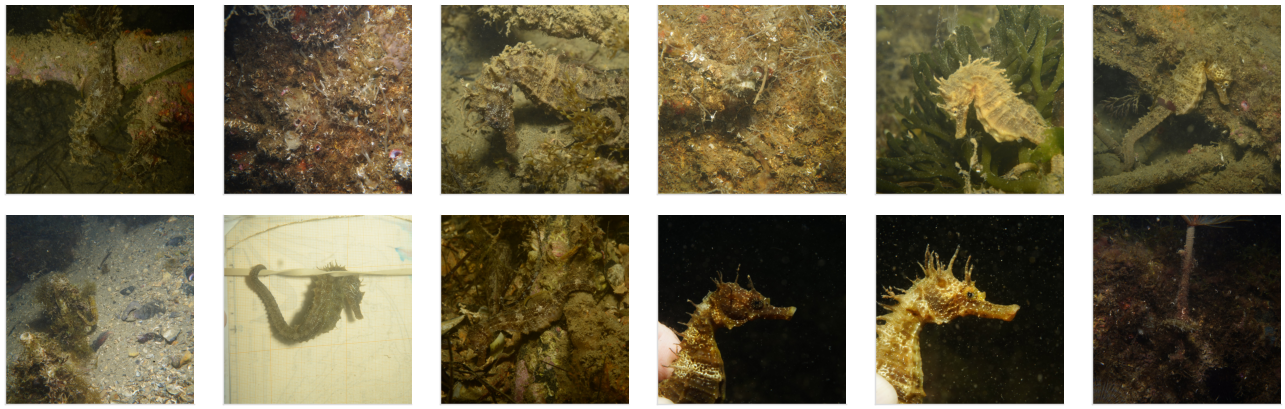

In [ ]:
import re

import numpy as np
from PIL import Image

# 'SH024_002_007_det0_cropped.jpg' -> individual 'SH024', observation number '002'. The photo number
# and SAM 3's suffixes (_det<n>, _segmented, _mask, _cropped, _annotated) are optional.
PHOTO_NAME = re.compile(r"^(?P<identity>SH\d+)_(?P<number>\d+)(?:_\d+)?"
                        r"(?:_det\d+|_segmented|_mask|_cropped|_annotated)*(?:\.[^.]+)?$")

N_TILES, ROWS, FIGURE_SEED = 12, 2, 7

# The first photograph of each individual, in name order. A name that does not follow the
# convention has no identity and is left out.
paths = pd.Series(sorted(PHOTOGRAPHS.glob("*.jpg")))
identity = paths.map(lambda path: path.name).str.extract(PHOTO_NAME)["identity"]
first_photograph = paths.groupby(identity).first()  # individuals sorted by name

rng = np.random.default_rng(FIGURE_SEED)
chosen = rng.choice(first_photograph.index, size=N_TILES, replace=False)
tiles = first_photograph[chosen].tolist()

columns = N_TILES // ROWS
figure, axes = plt.subplots(ROWS, columns, figsize=(1.7 * columns, 1.7 * ROWS))
for axis, path in zip(axes.ravel(), tiles):
    # The largest centred square of the photograph, so every tile has the same shape.
    image = Image.open(path).convert("RGB")
    side = min(image.size)
    left, top = (image.width - side) // 2, (image.height - side) // 2
    axis.imshow(image.crop((left, top, left + side, top + side)))
    # No ticks, no grid, a light frame.
    axis.set_xticks([])
    axis.set_yticks([])
    axis.grid(False)
    for spine in axis.spines.values():
        spine.set_color("#DDDDDD")
figure.subplots_adjust(wspace=0.02, hspace=0.02)
# PDF for LaTeX, PNG for a quick look.
figure.tight_layout(pad=1.2)
figure.savefig(FIGURE_DIR / "fig1_diversity.pdf")
figure.savefig(FIGURE_DIR / "fig1_diversity.png", dpi=200)
print(f"wrote {FIGURE_DIR / 'fig1_diversity'}.pdf and .png")
plt.show()